# Chapter 12: Optimization Algorithms

In [1]:
%matplotlib inline
import numpy as np
import torch
from mpl_toolkits import mplot3d
from d2l import torch as d2l

# 12.1 Optimization and Deep Learning
* Will be discussing relationship between optimizatio and deep learning, as well as challenges of using optimization in deep learning
* Usually define loss function first, then use an optimization algorithim to attempt to minimize overall loss
* In optimization language, loss function is often referred to as "objective function"
* Note, if we need to maximize an objective (rather than minimize), we can just flip the sign on the objective function

### 12.1.1 Goal of Optimization
* Deep Learning: Goal is to find a suitable model given finite data. Also want to minimize generalization error. Need to be wary of overfitting to given training dataset, along with naive optimization 
* Optimization: Minimize an objective (i.e. training loss)
* Recall:
    * Empirical Loss: Average loss on training dataset (which is subset of entire population data)
    * Risk: Expected loss on entire population of data

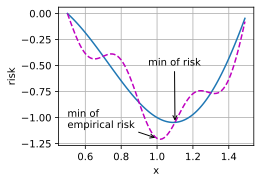

In [4]:
def f(x): # Risk Function
    return x * torch.cos(np.pi * x)

def g(x): # Empirical Risk Function
    return f(x) + 0.2 * torch.cos(5 * np.pi * x)


def annotate(text, xy, xytext):  
    d2l.plt.gca().annotate(text, xy=xy, xytext=xytext,
                           arrowprops=dict(arrowstyle='->'))

x = torch.arange(0.5, 1.5, 0.01)
d2l.set_figsize((4.5, 2.5))
d2l.plot(x, [f(x), g(x)], 'x', 'risk')
annotate('min of\nempirical risk', (1.0, -1.2), (0.5, -1.1))
annotate('min of risk', (1.1, -1.05), (0.95, -0.5))

### 12.1.2 Optimization Challenges in Deep Learning
* Most (if not all) optimization problems in deep learning are too complex for analytical solution, and thus numerical solutions must be employed
* All optimization algorithims that will be covered in Chapter 12 are of this category
* Some Challenges in Deep Learning
    1. Local Minima
    1. Saddle Points
    1. Vanishing Gradients


### 12.1.2.1 Local Minima
* Local minima vs Global minima
* Objective (i.e. loss) function of deep learning models usually has many local optima
* Numerical solution may only be local and not global minima (possibly due to gradient signal being zeor or close to it)
* At that point, some degree of noise may dislodge objective function from local minima. Minibatch Stochastic Gradient Descent provides a natural variation/noise to achieve this end

### 12.1.2.2 Saddle Points
* Any point/location where all gradients of a function vanish but it not a local or global minimum
* Optimization will stall at this point, even though it is not a minimum 
* Assume an input of a function is a k-dimensional vector and its output is a scalar, so its Hessian matrix will have $k$ eigenvalues. Solution of a function could be a (1) local minimum, (2) local maximum, (3) saddle point at a position where function gradient is zero
    1. When eigenvalues of the function's Hessian matrix at the zero-gradient position are all positive, we have a local minimum for the function
    1. When the eigenvalues of the function’s Hessian matrix at the zero-gradient position are all negative, we have a local maximum for the function.
    1. When the eigenvalues of the function’s Hessian matrix at the zero-gradient position are negative and positive, we have a saddle point for the function.
* Note - for high dimensional problems (as in deep learning) it is very likely that some of the eigenvalues are negative, which makes saddle points more likely than local minima
    * Exceptions to this situation: Convex Function (are functions where their eigenvalues of the Hessian are non-negative)

### 12.1.2.3 Vanishing Gradients
* Recall something like tanh, demonstrated again below
* For $f(x) = \text{tanh(x)}$, we have $ f'(x) = 1-\text{tanh}^2 (x)$, and thus $f'(4) = 0.0013$

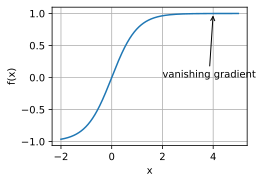

In [5]:
x = torch.arange(-2.0, 5.0, 0.01)
d2l.plot(x, [torch.tanh(x)], 'x', 'f(x)')
annotate('vanishing gradient', (4, 1), (2, 0.0))

### 12.1.3 Summary
* Minimizing training error does not garuntee we have found best set of parameters to minimize generalization error (which is the goal)
* Optimization problems may have many local minima and in DL usually require numerical methods
* Problem may have many more saddle points (than minima), as generally optimization problems in DL are non-convex
* Vanishing gradients can cause optimization to stall. Often can be aided by reparametrization. Good initialization is also helpful

### 12.1.4 Exercises
1. Consider a simple MLP with a single hidden layer of, say, $d$ dimensions in the hidden layer and a single output. Show that for any local minimum there are at least $d!$ equivalent solutions that behave identically.
1. Assume that we have a symmetric random matrix $\mathbf{M}$ where the entries
   $M_{ij} = M_{ji}$ are each drawn from some probability distribution
   $p_{ij}$. Furthermore assume that $p_{ij}(x) = p_{ij}(-x)$, i.e., that the
   distribution is symmetric (see e.g., Wigner.1958 for details).
    1. Prove that the distribution over eigenvalues is also symmetric. That is, for any eigenvector $\mathbf{v}$ the probability that the associated eigenvalue $\lambda$ satisfies $P(\lambda > 0) = P(\lambda < 0)$.
    1. Why does the above *not* imply $P(\lambda > 0) = 0.5$?
1. What other challenges involved in deep learning optimization can you think of?
1. Assume that you want to balance a (real) ball on a (real) saddle.
    1. Why is this hard?
    1. Can you exploit this effect also for optimization algorithms?

Exercise #1

Can write this simple MLP as:
$$ f(x) = \sum_i^d v_i \sigma(w_i^\top x + b_i) + c$$
Where $i=1, ..., n$ and $c\in \mathbb{R}$. 

For a given output $y=f(x)$, we have a set of parameters $\theta_y$ that was used to compute this output. Notice, we can re-arrange the order of neurons in the hidden layer to achieve the same output due to order not mattering in the summation operation performed at the single output neuron. Thus, we may order the $d$ hidden neurons in whatever order we wish, where order does not matter, and thus we have $d!$ equivalent solution (use permutations)


Exercise #2

* Each element of matrix $M$, $M_{ij}$ is drawn from a symmetrical probability distribution given by $p_{ij}(x) = p_{ij}(-x)$
* Eigenvalues $\lambda$ are defined as: $M v = \lambda v$, where $v$ is the corresponding eigenvector for $\lambda$, where we assume here that $\lambda >0$
* For $\lambda < 0$, that would require: $(-M)v = - \lambda v$. Since the matrix $M$ is defined where each of the elements are drawn from a symmetric probability distribution $p(x) = p(-x)$. Also, $M$ is symmetric s.t. $M_{ij} = M_{ji}$
* Due to symmetric probability distribution from which elements are drawn, that means $-M$ is just as likely as $M$. This results for a given eivenvalue/eigenvector combination of matrix $M$, $-\lambda$ and $\lambda$ are equally probable, thus $P(\lambda >0) = P(\lambda <0)$
* Note, this does not imply $P(\lambda >0)=0.5$, since would requires $P(\lambda = 0)=0$, and we have no garuntee of such

Exercise #3

* Exploding gradients
* Weird curvatures/manifolds in higher dimensions
* Need for adaptive learning rates?
* Possible global minima is never found and may have to settle for local minima

Exercise #4
1. Stable equilbrium in one direction, but unstable equilbirum in the orthogonal direction
1. The unstable equilbrium is our friend (in the case the saddle represents the loss function's landscape) where we know optimizatino will continue in the unstable direction but stall in the stable one, so we can adjust the learning rates accordingly based on how much the loss function has changed recently (simple-moving average?)

# 12.2 Convexity
* Convexity is useful in optimizaiton algorithim design due to the fact it is much easier to test/analyze algos in convex situations
* It sets an upper bound of expected performance (since deep learning is rarely convec) of algorithims performing bad in convex situations, we can expect it to be worse in realistic, non-convex situations
* Note, although deep learning is often non-convex, they may display properties of convex landscape near local minima

In [6]:
%matplotlib inline
import numpy as np
import torch
from mpl_toolkits import mplot3d
from d2l import torch as d2l

### 12.2.1 Definitions

### 12.2.2 Properties

### 12.2.3 Constraints

### 12.2.4 Summary

### 12.2.5 Exercises
1. Assume that we want to verify convexity of a set by drawing all lines between points within the set and checking whether the lines are contained.
    1. Prove that it is sufficient to check only the points on the boundary.
    1. Prove that it is sufficient to check only the vertices of the set.
1. Denote by $\mathcal{B}_p[r] \stackrel{\textrm{def}}{=} \{\mathbf{x} | \mathbf{x} \in \mathbb{R}^d \textrm{ and } \|\mathbf{x}\|_p \leq r\}$ the ball of radius $r$ using the $p$-norm. Prove that $\mathcal{B}_p[r]$ is convex for all $p \geq 1$.
1. Given convex functions $f$ and $g$, show that $\mathrm{max}(f, g)$ is convex, too. Prove that $\mathrm{min}(f, g)$ is not convex.
1. Prove that the normalization of the softmax function is convex. More specifically prove the convexity of
    $f(x) = \log \sum_i \exp(x_i)$.
1. Prove that linear subspaces, i.e., $\mathcal{X} = \{\mathbf{x} | \mathbf{W} \mathbf{x} = \mathbf{b}\}$, are convex sets.
1. Prove that in the case of linear subspaces with $\mathbf{b} = \mathbf{0}$ the projection $\textrm{Proj}_\mathcal{X}$ can be written as $\mathbf{M} \mathbf{x}$ for some matrix $\mathbf{M}$.
1. Show that for  twice-differentiable convex functions $f$ we can write $f(x + \epsilon) = f(x) + \epsilon f'(x) + \frac{1}{2} \epsilon^2 f''(x + \xi)$ for some $\xi \in [0, \epsilon]$.
1. Given a convex set $\mathcal{X}$ and two vectors $\mathbf{x}$ and $\mathbf{y}$, prove that projections never increase distances, i.e., $\|\mathbf{x} - \mathbf{y}\| \geq \|\textrm{Proj}_\mathcal{X}(\mathbf{x}) - \textrm{Proj}_\mathcal{X}(\mathbf{y})\|$.


Exercise #1

1. Intuitively makes sense. Take 2 arbitrary points that are contained in the set in question. Draw a line connecting them, and then extend the line in both directions until they both meet the boundary. Call this line marked by b1, p1, p2, b2 where p's are the original arbitrary points and b's are points along the boundaries. We can see that if the boundary points are contained within the set, then by virtue of p1-p2 being a subset of the line segment b1-b2, then p1-p2 are automatically in the set and thus convex. Probably formalize this with the convex line definitio nwith $\lambda \in (0, 1)$ to characterize the p1-p2 line
1. Also intuitively makes sense. Requires polygonic-set. Consider verticies $V = \{v_1, \dots, v_n \}$. Recall the convex hull: $H(V) = \{ \sum_{i=1}^n \alpha_i v_i : \alpha_i \geq 0, \sum_{i=1}^n \alpha_i = 1 \}$. Note that a convex hull is defined as a the smallest convex shape that contains all the points.
    * Suppose $S=H(V)$. Then, any two arbitrary points $p_1, p_2, \in S$ can be written as $p_1 = \sum_{i=1}^n \alpha_i v_i, p_2 = \sum_{i=1}^n \beta_i v_i$ where $\sum_{i=1}^n \alpha_i = \sum_{i=1}^n \beta_i = 1$
    * To text convexity between $p_1, p_2$, we test: $\lambda p_1 + (1-\lambda) p_2 \in S $. Substituting in the expressions for $p_1, p_2$ from above and re-arranging, we get: $\sum_{i=1}^n (\lambda \alpha_i + (1-\lambda)\beta_i )v_i$. We can also define $$\gamma_i \equiv \lambda \alpha_i + (1-\lambda)\beta_i$$
    * Recall that $\gamma_i \geq 0$ due to its definition and how $\alpha_i, \beta_i, \text{and} \gamma$ are defined. Also, we know that $1 = \sum_{i=1}^n \gamma_i$ since looking at the LHS of the convex text expression, substituting in the expressiosn for $p_1, p_2$, we find that the LHS is equal to 1, and thus the $\gamma_i$'s are normalized to 1. 
    * Thus, we can conclude that every point on the line connecting any 2 arbitrary points $p_1, p_2 \in S$ can be represented as a weighted linear combination of the vertices and is convex. Thus, we just need to verify that the vertex points are convex, then it is garunteed that the set is convex. 
    * Note above, $S$ was set equal to the convex hull, not the original set in consideration. Need to verify/ensure that $H(V) \subseteq \text{Original Set}$

Exercise #2

* Prove that $\beta_p [r]$ is convex for  all $p \geq 1$ where $\beta_p [r] \equiv \{ \mathbf{x} | \mathbf{x} \in \mathbb{R}^d \text{and} ||x||_p \leq r \}$
* Want so show that any arbitrary $\mathbf{x_1}, \mathbf{x_2} \in \beta_p$, which means we want so show: $$ || \lambda \mathbf{x_1} + (1-\lambda)\mathbf{x_2} ||_p \leq r$$ 
* Recall that the p-norm is defined as: $\|\mathbf{x}\|_p = \left( \sum_{i=1}^n |x_i|^p \right)^{1/p}$
* Use the triangle property of norms: $ || x + y|| \leq ||x| + ||y|| $ and factor out the constants. Ignore the fact that the original expression is $\leq r$ right now. 
    * $ || \lambda \mathbf{x_1} + (1-\lambda)\mathbf{x_2} ||_p \leq \lambda || \mathbf{x_1} || + (1-\lambda) ||\mathbf{x_2} || $
    * We know that $\mathbf{x_1}$ and $\mathbf{x_2}$ have p-norms $\leq r$ already by definition
    * Thus, $\lambda || \mathbf{x_1} || + (1-\lambda) ||\mathbf{x_2} || \leq \lambda r + (1-\lambda) r = r$
    * Thus, we have shown that any 2 arbitrary $\mathbf{x_1, x_2} \in \beta_p(r)$ for all $p \geq 1$, concluding our proof

Exercise #3

* Given functions $f, g$ that are known to be convex, then prove that:
    1. $\text{max}(f, g)$ is convex
    1. $\text{min}(f, g)$ is non-convex
1. Prove that $\text{max}(f, g)$ is convex
    * Recall, convex functions are defined as satisfying the criteria: 
    $$\lambda f(x_1) + (1-\lambda)f(x_2) \geq f(\lambda x_1 + (1-\lambda)x_2)$$
    $$\lambda g(x_1) + (1-\lambda)g(x_2) \geq g(\lambda x_1 + (1-\lambda)x_2)$$
    * $h(x) = \text{max}(f(x), g(x))$ 
    * Need to show: $$ h(\lambda x_1 + (1-\lambda) x_2 ) \leq \lambda h(x_1) + (1-\lambda) h(x_2)$$
    * Try working from LHS to RHS
    $$ h(\lambda x_1 + (1-\lambda) x_2 ) = \text{max}(f(\lambda x_1 + (1-\lambda) x_2), g(\lambda x_1 + (1-\lambda) x_2))$$
    * By construction, we know that: 
    $$ f(x_1) \leq h(x_1); g(x_1) \leq h(x_1); f(x_2) \leq h(x_2); g(x_2) \leq h(x_2) $$
    * Substituting said expressions into expressions for convexity of $f(x), g(x)$, we get: 
    $$ \lambda f(x_1) + (1-\lambda)f(x_2) \leq \lambda h(x_1) + (1-\lambda)h(x_2) $$
    $$ \lambda g(x_1) + (1-\lambda)g(x_2) \leq \lambda h(x_1) + (1-\lambda)h(x_2)$$
    * Thus, we can write the following by definitino of convex functions:
    $$ f(\lambda x_1 + (1-\lambda)x_2) \leq \lambda h(x_1) + (1-\lambda) h(x_2)$$
    $$ g(\lambda x_1 + (1-\lambda)x_2) \leq \lambda h(x_1) + (1-\lambda) h(x_2)$$
    * Recall this line from earlier and substitute in :
    $$ h(\lambda x_1 + (1-\lambda) x_2 ) = \text{max}(f(\lambda x_1 + (1-\lambda) x_2), g(\lambda x_1 + (1-\lambda) x_2))$$
    $$ h(\lambda x_1 + (1-\lambda) x_2 ) \geq \text{max}(f(\lambda x_1 + (1-\lambda) x_2), g(\lambda x_1 + (1-\lambda) x_2)) = h(\lambda x_1 + (1-\lambda)x_2)$$
    $$ h(\lambda x_1 + (1-\lambda) x_2) \leq \lambda h(x_1) + (1-\lambda) h(x_2) $$
    * Thus, we have shown convexity of $\text{max}(f, g)$
1. Prove that $\text{min}(f, g)$ is non-convex
    * Try providing counterexample of convexity by setting: $f(x), g(x)$
    * $h(x) = \text{min}(f(x), g(x))$
    * Convex Definition:
    $$ \lambda h(x_1) + (1-\lambda) h(x_2) \geq h(\lambda x_1 + (1-\lambda) x_2) $$
    * Try out: $f(x)=x, g(x)=-x$. Will result in $h(x) = -|x|$. Derive of knowing how convexity tests/formulas work and try to work around it
    * Test out convexity for $x_1 = -1, x_2 = +1, \lambda=0.5$
    * Convexity Test: $\lambda h(x_1) + (1-\lambda)h(x_2) \geq h(\lambda x_1 + (1-\lambda)x_2)$
    * Substitute in values: 
    $$ (0.5)h(-1) + (0.5)h(1) = (-0.5) + (-0.5) = -1 \geq h( (0.5)(-1) + (0.5)(1) ) = h(0) =0 $$
    $$ -1 \geq 0$$

# 12.3 Gradient Descent

### 12.3.1 One-Dimensional Gradient Descent

### 12.3.2 Multivariate Gradient Descent

### 12.3.3 Adaptive Methods

### 12.3.4 Summary

### 12.3.5 Exercises
1. Experiment with different learning rates and objective functions for gradient descent.
1. Implement line search to minimize a convex function in the interval $[a, b]$.
    1. Do you need derivatives for binary search, i.e., to decide whether to pick $[a, (a+b)/2]$ or $[(a+b)/2, b]$.
    1. How rapid is the rate of convergence for the algorithm?
    1. Implement the algorithm and apply it to minimizing $\log (\exp(x) + \exp(-2x -3))$.
1. Design an objective function defined on $\mathbb{R}^2$ where gradient descent is exceedingly slow. Hint: scale different coordinates differently.
1. Implement the lightweight version of Newton's method using preconditioning:
    1. Use diagonal Hessian as preconditioner.
    1. Use the absolute values of that rather than the actual (possibly signed) values.
    1. Apply this to the problem above.
1. Apply the algorithm above to a number of objective functions (convex or not). What happens if you rotate coordinates by $45$ degrees?


# 12.4 Stochastic Gradient Descent

### 12.4.1 Stochastic Gradient Updates

### 12.4.2 Dynamic Learning Rate

### 12.4.3 Convergence Analysis for Convex Objectives

### 12.4.4 Stochastic Gradients and Finite Samples

### 12.4.5 Summary

### 12.4.6 Exercises
1. Experiment with different learning rate schedules for stochastic gradient descent and with different numbers of iterations. In particular, plot the distance from the optimal solution $(0, 0)$ as a function of the number of iterations.
1. Prove that for the function $f(x_1, x_2) = x_1^2 + 2 x_2^2$ adding normal noise to the gradient is equivalent to minimizing a loss function $f(\mathbf{x}, \mathbf{w}) = (x_1 - w_1)^2 + 2 (x_2 - w_2)^2$ where $\mathbf{x}$ is drawn from a normal distribution.
1. Compare convergence of stochastic gradient descent when you sample from $\{(x_1, y_1), \ldots, (x_n, y_n)\}$ with replacement and when you sample without replacement.
1. How would you change the stochastic gradient descent solver if some gradient (or rather some coordinate associated with it) was consistently larger than all the other gradients?
1. Assume that $f(x) = x^2 (1 + \sin x)$. How many local minima does $f$ have? Can you change $f$ in such a way that to minimize it one needs to evaluate all the local minima?


# 12.5 Minibatch Stochastic Gradient Descent

### 12.5.1 Vectorization and Caches

### 12.5.2 Minibatches

### 12.5.3 Reading the Dataset

### 12.5.4 Implementation from Scratch

### 12.5.5 Concise Implementation

### 12.5.6 Summary

### 12.5.7 Exercises
1. Modify the batch size and learning rate and observe the rate of decline for the value of the objective function and the time consumed in each epoch.
1. Read the MXNet documentation and use the `Trainer` class `set_learning_rate` function to reduce the learning rate of the minibatch stochastic gradient descent to 1/10 of its previous value after each epoch.
1. Compare minibatch stochastic gradient descent with a variant that actually *samples with replacement* from the training set. What happens?
1. An evil genie replicates your dataset without telling you (i.e., each observation occurs twice and your dataset grows to twice its original size, but nobody told you). How does the behavior of stochastic gradient descent, minibatch stochastic gradient descent and that of gradient descent change?

# 12.6 Momentum

### 12.6.1 Basics

### 12.6.2 Practical Experiments

### 12.6.3 Theoretical Analysis

### 12.6.4 Summary

### 12.6.5 Exercises
1. Use other combinations of momentum hyperparameters and learning rates and observe and analyze the different experimental results.
1. Try out gradient descent and momentum for a quadratic problem where you have multiple eigenvalues, i.e., $f(x) = \frac{1}{2} \sum_i \lambda_i x_i^2$, e.g., $\lambda_i = 2^{-i}$. Plot how the values of $x$ decrease for the initialization $x_i = 1$.
1. Derive minimum value and minimizer for $h(\mathbf{x}) = \frac{1}{2} \mathbf{x}^\top \mathbf{Q} \mathbf{x} + \mathbf{x}^\top \mathbf{c} + b$.
1. What changes when we perform stochastic gradient descent with momentum? What happens when we use minibatch stochastic gradient descent with momentum? Experiment with the parameters?


# 12.7 Adagrad

### 12.7.1 Sparse Features and Learning Rates

### 12.7.2 Preconditioning

### 12.7.3 The Algorithm

### 12.7.4 Implementation from Scratch

### 12.7.5 Concise Implementation

### 12.7.6 Summary

### 12.7.7 Exercises
1. Prove that for an orthogonal matrix $\mathbf{U}$ and a vector $\mathbf{c}$ the following holds: $\|\mathbf{c} - \mathbf{\delta}\|_2 = \|\mathbf{U} \mathbf{c} - \mathbf{U} \mathbf{\delta}\|_2$. Why does this mean that the magnitude of perturbations does not change after an orthogonal change of variables?
1. Try out Adagrad for $f(\mathbf{x}) = 0.1 x_1^2 + 2 x_2^2$ and also for the objective function was rotated by 45 degrees, i.e., $f(\mathbf{x}) = 0.1 (x_1 + x_2)^2 + 2 (x_1 - x_2)^2$. Does it behave differently?
1. Prove [Gerschgorin's circle theorem](https://en.wikipedia.org/wiki/Gershgorin_circle_theorem) which states that eigenvalues $\lambda_i$ of a matrix $\mathbf{M}$ satisfy $|\lambda_i - \mathbf{M}_{jj}| \leq \sum_{k \neq j} |\mathbf{M}_{jk}|$ for at least one choice of $j$.
1. What does Gerschgorin's theorem tell us about the eigenvalues of the diagonally preconditioned matrix $\textrm{diag}^{-\frac{1}{2}}(\mathbf{M}) \mathbf{M} \textrm{diag}^{-\frac{1}{2}}(\mathbf{M})$?
1. Try out Adagrad for a proper deep network, such as LeNet Section when applied to Fashion-MNIST.
1. How would you need to modify Adagrad to achieve a less aggressive decay in learning rate?

# 12.8 RMSProp

### 12.8.1 The Algorithm

### 12.8.2 Implementation from Scratch

### 12.8.3 Concise Implementation

### 12.8.4 Summary

### 12.8.5 Exercises
1. What happens experimentally if we set $\gamma = 1$? Why?
1. Rotate the optimization problem to minimize $f(\mathbf{x}) = 0.1 (x_1 + x_2)^2 + 2 (x_1 - x_2)^2$. What happens to the convergence?
1. Try out what happens to RMSProp on a real machine learning problem, such as training on Fashion-MNIST. Experiment with different choices for adjusting the learning rate.
1. Would you want to adjust $\gamma$ as optimization progresses? How sensitive is RMSProp to this?


# 12.9 Adadelta

### 12.9.1 The Algorithm

### 12.9.2 Implementation

### 12.9.3 Summary

### 12.9.4 Exercises
1. Adjust the value of $\rho$. What happens?
1. Show how to implement the algorithm without the use of $\mathbf{g}_t'$. Why might this be a good idea?
1. Is Adadelta really learning rate free? Could you find optimization problems that break Adadelta?
1. Compare Adadelta to Adagrad and RMS prop to discuss their convergence behavior.

# 12.10 Adam

### 12.10.1 The Algorithm

### 12.10.2 Implementation

### 12.10.3 Yogi

### 12.10.4 Summary

### 12.10.5 Exercises
1. Adjust the learning rate and observe and analyze the experimental results.
1. Can you rewrite momentum and second moment updates such that it does not require bias correction?
1. Why do you need to reduce the learning rate $\eta$ as we converge?
1. Try to construct a case for which Adam diverges and Yogi converges?

# 12.11 Learning Rate Scheduling

### 12.11.1 Toy Problem

### 12.11.2 Schedulers

### 12.11.3 Policies

### 12.11.4 Summary

### 12.11.5 Exercises
1. Experiment with the optimization behavior for a given fixed learning rate. What is the best model you can obtain this way?
1. How does convergence change if you change the exponent of the decrease in the learning rate? Use `PolyScheduler` for your convenience in the experiments.
1. Apply the cosine scheduler to large computer vision problems, e.g., training ImageNet. How does it affect performance relative to other schedulers?
1. How long should warmup last?
1. Can you connect optimization and sampling? Start by using results from Welling.Teh.2011 on Stochastic Gradient Langevin Dynamics.
